# Activity 2.6 — Pokémon GO Kanto shortlist

## Decision question

> Using the supplied classroom dataset and the scoring rule below, is Charizard among the five Kanto Pokémon selected for tournament preparation?

This is a decision-analysis exercise. The data is synthetic and the score is a classroom proxy. It does **not** establish official tournament legality or competitive strength. Official Pokémon GO rules must be checked separately.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path('data/pokemon_go_kanto_candidates.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('activities/2.6-github-project-home/data/pokemon_go_kanto_candidates.csv')

candidates = pd.read_csv(DATA_PATH)
candidates.head()

,pokedex_id,pokemon,type_1,type_2,great_league_eligible,attack_index,bulk_index,move_coverage_index,meta_signal_index,source_note
0,1,Venusaur,Grass,Poison,True,67,78,83,78,classroom proxy
1,3,Charizard,Fire,Flying,True,82,55,86,84,classroom proxy
2,6,Blastoise,Water,NaN,True,65,82,76,75,classroom proxy
3,15,Beedrill,Bug,Poison,True,72,48,74,63,classroom proxy
4,18,Pidgeot,Normal,Flying,True,61,76,81,70,classroom proxy


## 1. Inspect the data

Before calculating a score, check shape, missing values, types, and the meaning of the eligibility flag. The flag is an instructional assumption, not an official ruling.

In [6]:
print(f'Rows: {len(candidates):,}')
print(f'Columns: {len(candidates.columns):,}')
display(candidates.dtypes.to_frame('dtype'))
display(candidates.isna().sum().to_frame('missing_values'))
#display(candidates.describe(numeric_only=True).T.round(2))

Rows: 15
Columns: 10


,dtype
pokedex_id,int64
pokemon,object
type_1,object
type_2,object
great_league_eligible,bool
attack_index,int64
bulk_index,int64
move_coverage_index,int64
meta_signal_index,int64
source_note,object


,missing_values
pokedex_id,0
pokemon,0
type_1,0
type_2,6
great_league_eligible,0
attack_index,0
bulk_index,0
move_coverage_index,0
meta_signal_index,0
source_note,0


## 2. Declare the classroom selection rule

We will rank only rows marked `great_league_eligible == True` and compute a weighted score:

`score = 0.30 × attack + 0.30 × bulk + 0.20 × move coverage + 0.20 × meta signal`

The weights are a teaching choice. They should be challenged, justified, and tested. A different objective—such as team coverage, cost, or current move performance—could produce a different shortlist.

In [3]:
weights = {
    'attack_index': 0.30,
    'bulk_index': 0.30,
    'move_coverage_index': 0.20,
    'meta_signal_index': 0.20,
}

eligible = candidates.loc[candidates['great_league_eligible']].copy()
eligible['decision_score'] = sum(eligible[column] * weight for column, weight in weights.items())
ranking = eligible.sort_values('decision_score', ascending=False).reset_index(drop=True)
ranking['rank'] = ranking.index + 1
selected_five = ranking.head(5)
display(selected_five[['rank', 'pokemon', 'decision_score', 'type_1', 'type_2']].round({'decision_score': 2}))

,rank,pokemon,decision_score,type_1,type_2
0,1,Snorlax,85.6,Normal,NaN
1,2,Lapras,84.1,Water,Ice
2,3,Poliwrath,81.6,Water,Fighting
3,4,Nidoqueen,80.2,Poison,Ground
4,5,Slowbro,78.9,Water,Psychic


In [ ]:
charizard = ranking.loc[ranking['pokemon'].eq('Charizard')].iloc[0]
is_selected = charizard['rank'] <= 5
print(f"Charizard rank: {int(charizard['rank'])} of {len(ranking)}")
print(f"Charizard is among the selected five: {'YES' if is_selected else 'NO'}")
print('This answer applies only to the declared classroom proxy rule.')

## 3. Visualize the shortlist

A chart is useful only if it helps a decision-maker understand the ranking and its limitations.

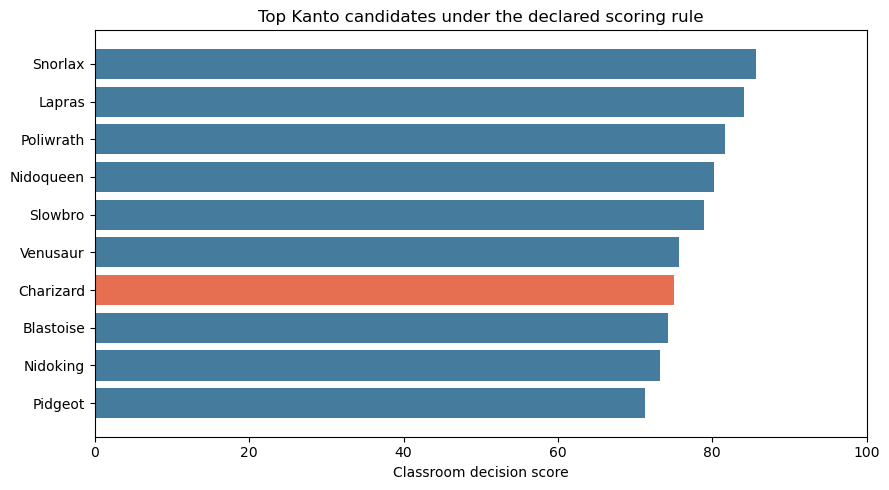

In [4]:
plot_data = ranking.head(10).sort_values('decision_score')
colors = ['#e76f51' if name == 'Charizard' else '#457b9d' for name in plot_data['pokemon']]
plt.figure(figsize=(9, 5))
plt.barh(plot_data['pokemon'], plot_data['decision_score'], color=colors)
plt.xlabel('Classroom decision score')
plt.title('Top Kanto candidates under the declared scoring rule')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

## 4. Sensitivity analysis

A robust decision should not depend on one arbitrary set of weights. Here we compare three plausible perspectives.

In [5]:
scenarios = {
    'Balanced': weights,
    'Bulk-first': {'attack_index': 0.15, 'bulk_index': 0.45, 'move_coverage_index': 0.20, 'meta_signal_index': 0.20},
    'Meta-first': {'attack_index': 0.20, 'bulk_index': 0.20, 'move_coverage_index': 0.20, 'meta_signal_index': 0.40},
}

scenario_rows = []
for scenario, scenario_weights in scenarios.items():
    scored = eligible.copy()
    scored['decision_score'] = sum(scored[column] * weight for column, weight in scenario_weights.items())
    scored = scored.sort_values('decision_score', ascending=False).head(5)
    scenario_rows.append({'scenario': scenario, 'selected_five': ', '.join(scored['pokemon'])})

display(pd.DataFrame(scenario_rows))

,scenario,selected_five
0,Balanced,"Snorlax, Lapras, Poliwrath, Nidoqueen, Slowbro"
1,Bulk-first,"Snorlax, Lapras, Poliwrath, Nidoqueen, Slowbro"
2,Meta-first,"Snorlax, Lapras, Poliwrath, Nidoqueen, Slowbro"


## 5. Interpretation and next evidence

Write a short conclusion answering the question. Then address these operational checks:

- Does the current event use Great League or a different format?
- Is each candidate legal under the current event’s restrictions and banned list?
- Does the candidate have a usable build at or below the relevant CP limit?
- Do moves, IVs, team synergy, shield scenarios, and current meta data change the decision?
- What data source, date, and version would make the conclusion reproducible?

The official references are listed in the activity README. Cite the exact version you reviewed and do not treat this notebook’s proxy score as an official tournament recommendation.